In [1]:
pip install rdkit duckdb pandas numpy seaborn matplotlib mols2grid scikit-learn lightgbm scipy wget tqdm useful_rdkit_utils


Note: you may need to restart the kernel to use updated packages.


In [2]:
import wget
wget.download("https://raw.githubusercontent.com/PatWalters/practical_cheminformatics_tutorials/refs/heads/main/bindingdb/download_pdb_ids.py")

'download_pdb_ids (1).py'

In [3]:
# removing annoying messages
import warnings
from pathlib import Path

# database access
import duckdb
# chemiformatics
from rdkit import Chem
from rdkit import DataStructs
from rdkit.Chem import rdFingerprintGenerator
import mols2grid
# handling matrices and arrays
import numpy as np
# data tables
import pandas as pd
# plotting
import matplotlib.pyplot as plt
import seaborn as sns
import useful_rdkit_utils as uru
# file downloads
import wget
# machine learning
from lightgbm import LGBMRegressor
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
# progress bars
from tqdm.auto import tqdm

# get info from the pdb
from download_pdb_ids import get_pdb_ids

In [4]:
tqdm.pandas()

In [5]:
uniprot_id = "O75469"

In [6]:
file_path = Path("bindingdb_sample.ddb")

if not file_path.exists():
    url = "https://raw.githubusercontent.com/PatWalters/practical_cheminformatics_tutorials/refs/heads/main/bindingdb/bindingdb_sample.ddb"
    fiiename = wget.download(url)

In [7]:
con = duckdb.connect(file_path,read_only=True)
columns = con.table('bindingdb').columns
pd.DataFrame(columns[:50],columns=["Column Name"])

,Column Name
0,BindingDB Reactant_set_id
1,Ligand SMILES
2,Ligand InChI
3,Ligand InChI Key
4,BindingDB MonomerID
5,BindingDB Ligand Name
6,Target Name
7,Target Source Organism According to Curator or...
8,Ki (nM)
9,IC50 (nM)


In [8]:
query = f"""select "Ligand SMILES","Ligand InChI Key",
    "BindingDB Ligand Name",
    "Target Name", 
    "Target Source Organism According to Curator or DataSource",
    "Article DOI", 
    "PDB ID(s) for Ligand-Target Complex",
    "EC50 (nM)" from bindingdb 
    where "UniProt (SwissProt) Primary ID of Target Chain 1" = '{uniprot_id}'"""

In [9]:
res = con.execute(query)
res_df = res.df()

In [10]:
res_df.head()

,Ligand SMILES,Ligand InChI Key,BindingDB Ligand Name,Target Name,Target Source Organism According to Curator or DataSource,Article DOI,PDB ID(s) for Ligand-Target Complex,EC50 (nM)
0,c1ccc(cc1)S(=O)(=O)[N@@](CC(F)(F)F)c2ccc(cc2)C...,SGIWFELWJPNFDH-UHFFFAOYSA-N,"CHEMBL62136::[3H]T0901317::T 0901317::N-[4-(1,...",Nuclear receptor subfamily 1 group I member 2,Homo sapiens,10.1016/j.bmc.2006.12.026,"1UPV,1UPW,1PQC,5NTQ,4NB6,5K3L,1UHL,5EJV,2O9I",13
1,OC(c1ccc(cc1)N(CC(F)(F)F)S(=O)(=O)c1ccccc1)C(F...,YKHCWWRCGHFHFR-UHFFFAOYSA-N,"N-[4-(2,2,2-trifluoro-1-hydroxyethyl)phenyl]-N...",Nuclear receptor subfamily 1 group I member 2,Homo sapiens,10.1016/j.bmc.2006.12.026,NaN,1000
2,CC(O)(c1ccc(cc1)N(CC(F)(F)F)S(=O)(=O)c1ccccc1)...,DKJFEFWRUFUJLQ-UHFFFAOYSA-N,"N-[4-(1,1,1-trifluoro-2-hydroxypropan-2-yl)phe...",Nuclear receptor subfamily 1 group I member 2,Homo sapiens,10.1016/j.bmc.2006.12.026,NaN,501
3,CCC(O)(c1ccc(cc1)N(CC(F)(F)F)S(=O)(=O)c1ccccc1...,JXXXEUFWXBYGGF-UHFFFAOYSA-N,"N-[4-(1,1,1-trifluoro-2-hydroxybutan-2-yl)phen...",Nuclear receptor subfamily 1 group I member 2,Homo sapiens,10.1016/j.bmc.2006.12.026,NaN,126
4,CCCC(O)(c1ccc(cc1)N(CC(F)(F)F)S(=O)(=O)c1ccccc...,REGGUSMKWKQUJO-UHFFFAOYSA-N,"N-[4-(1,1,1-trifluoro-2-hydroxypentan-2-yl)phe...",Nuclear receptor subfamily 1 group I member 2,Homo sapiens,10.1016/j.bmc.2006.12.026,NaN,158


In [11]:
res_df["has_operator"] = res_df["EC50 (nM)"].str.startswith((">","<"))

In [12]:
res_df = res_df.query("`EC50 (nM)`.notna() and has_operator == False")

In [13]:
res_df['pEC50'] = -np.log10(res_df["EC50 (nM)"].astype(float) * 1e-9)

In [14]:
ref_count_df = uru.value_counts_df(res_df,"Article DOI")
ref_dict = ref_count_df.set_index('Article DOI')['count'].to_dict()
ref_count_df.head(20)

,Article DOI,count
0,10.1124/dmd.110.035105,166
1,10.1021/acs.jmedchem.0c02201,66
2,10.1016/j.bmc.2008.02.020,31
3,10.1016/j.bmcl.2020.127392,29
4,10.1021/acs.jmedchem.9b01032,26
5,10.1016/j.bmcl.2017.12.006,24
6,10.1016/j.bmcl.2020.127441,20
7,10.1021/ml500144h,19
8,10.1021/acsmedchemlett.3c00210,18
9,10.1021/acsmedchemlett.9b00010,16


In [15]:
def aggregate_data(df):
    res_list = []
    for k,v in df.groupby("Ligand InChI Key"):
        res_list.append([v['Ligand SMILES'].values[0],v.pEC50.mean()])
    return pd.DataFrame(res_list,columns=["SMILES","pEC50"])

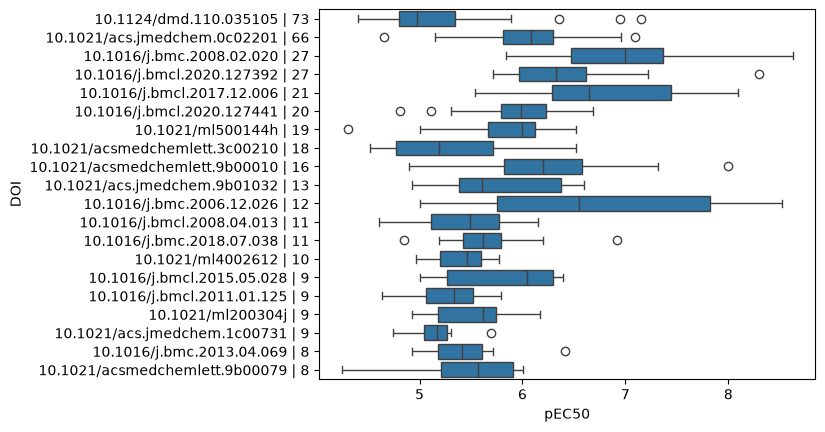

In [16]:
assay_df_list = []
y_label_list = []
for doi in ref_count_df["Article DOI"].head(20):
    doi_df = res_df.query("`Article DOI`== @doi")  
    agg_df = aggregate_data(doi_df)
    label = f"{doi} | {len(agg_df)}"
    agg_df['label'] = label
    y_label_list.append([label,len(agg_df)])
    assay_df_list.append(agg_df) 
combo_df = pd.concat(assay_df_list).reset_index(drop=True)
y_label_df = pd.DataFrame(y_label_list,columns=["label","count"]).sort_values("count",ascending=False)
ax = sns.boxplot(x="pEC50",y="label",data=combo_df,order=y_label_df.label)
ax.set_ylabel("DOI");

In [17]:
def get_max_tanimoto_similarities(smiles_list, radius=2, nBits=2048):
    """
    Calculates the maximum Tanimoto similarity for each molecule 
    compared to all other molecules in the provided SMILES list
    using the modern MorganGenerator.
    """
    # 1. Convert SMILES to RDKit Mol objects
    mols = [Chem.MolFromSmiles(s) for s in smiles_list]
    valid_mols = [m for m in mols if m is not None]
    
    if not valid_mols:
        return []

    # 2. Initialize the Morgan Fingerprint Generator
    # Note: radius=2 in the old method corresponds to fpSize=2 in the generator
    generator = rdFingerprintGenerator.GetMorganGenerator(radius=radius, fpSize=nBits)
    
    # 3. Generate fingerprints
    fps = [generator.GetFingerprint(m) for m in valid_mols]
    
    max_similarities = []
    
    # 4. Compare each fingerprint against all others
    for i, fp_target in enumerate(fps):
        # Using BulkTanimotoSimilarity for better performance
        others = fps[:i] + fps[i+1:]
        
        if not others:
            max_similarities.append(0.0)
            continue
            
        sims = DataStructs.BulkTanimotoSimilarity(fp_target, others)
        max_similarities.append(max(sims))
        
    return max_similarities

In [18]:
sim_df_list = []
for k,v in combo_df.groupby("label"):
    smiles_list = v.SMILES
    sim_list = get_max_tanimoto_similarities(smiles_list)
    sim_df = pd.DataFrame(sim_list,columns=["sim"])
    sim_df['label'] = k
    sim_df_list.append(sim_df)
sim_combo_df = pd.concat(sim_df_list)

<Axes: xlabel='sim', ylabel='label'>

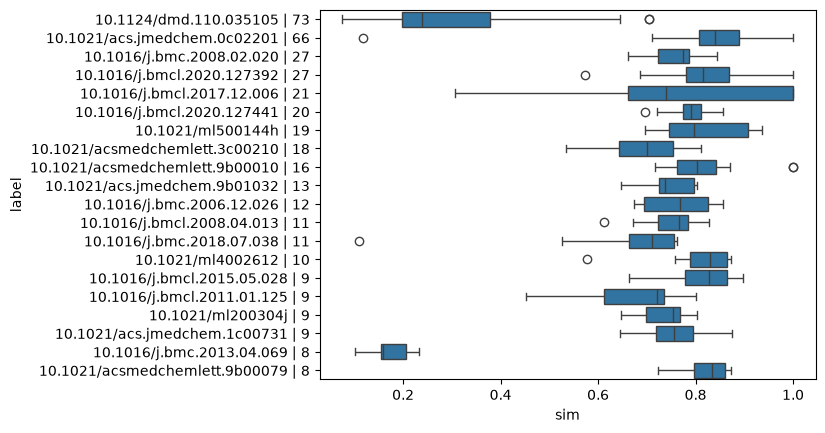

In [19]:
sns.boxplot(x="sim",y="label",data=sim_combo_df,order=y_label_df.label)

In [20]:
pxr_id_list = get_pdb_ids(uniprot_id)
pxr_id_set = set([x.upper() for x in pxr_id_list])

In [23]:
pxr_pdb_list = []
for r in res_df["PDB ID(s) for Ligand-Target Complex"]:
    if pd.isna(r):
        pxr_pdb_list.append(None)
    else:
        id_list = r.split(",")
        ok_list = [x for x in id_list if x in pxr_id_set]
        if len(ok_list):
            pxr_pdb_list.append(ok_list)
        else:
            pxr_pdb_list.append(None)

In [24]:
res_df['pxr_pdb'] = pxr_pdb_list

In [25]:
xray_df = res_df.dropna(subset="pxr_pdb")[["Ligand SMILES","Article DOI","pxr_pdb"]].dropna().drop_duplicates(subset="Article DOI")

In [26]:
mols2grid.display(xray_df,smiles_col="Ligand SMILES",subset=["img","pxr_pdb"])

In [27]:
res_df_ok = res_df.query("has_operator == False").copy()
ligand_count_df = uru.value_counts_df(res_df_ok,"Ligand InChI Key")
ligand_count_df.sort_values("count",ascending=False,inplace=True)

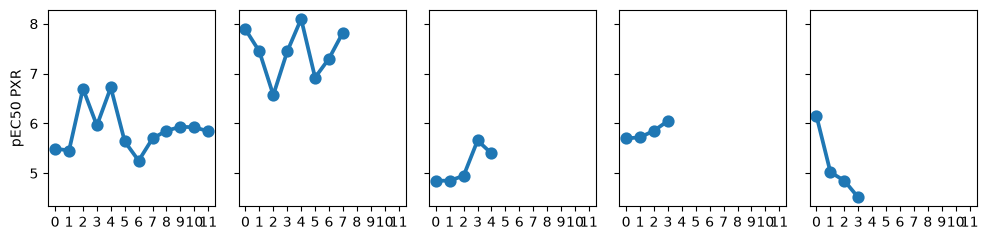

In [28]:
figure, axes = plt.subplots(1,5,figsize=(10,2.5),sharex=True,sharey=True)
for i,inchi in enumerate(ligand_count_df.head(5)["Ligand InChI Key"]):
    vals = res_df_ok.query("`Ligand InChI Key` == @inchi").pEC50.values
    ax = sns.pointplot(vals,ax=axes[i])
    ax.set_label("Sample #")
    ax.set_ylabel("pEC50 PXR")
plt.tight_layout()

In [29]:
agg_list = []
for k,v in res_df_ok.groupby("Ligand InChI Key"):
    mean_val = v.pEC50.values.mean()
    smiles = v["Ligand SMILES"].values[0]
    agg_list.append([smiles,mean_val])
agg_df = pd.DataFrame(agg_list,columns=["SMILES","pEC50"])

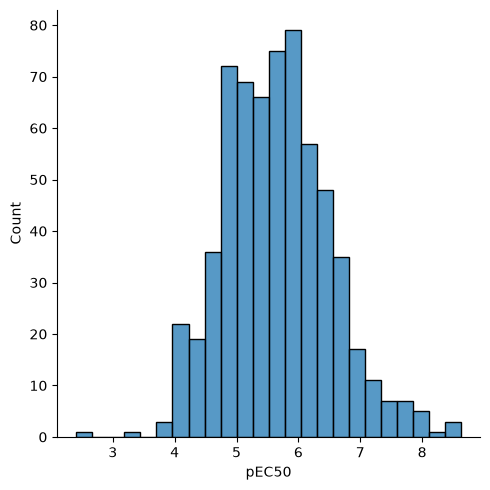

In [30]:
sns.displot(agg_df.pEC50)

In [31]:
rdkit_desc = uru.RDKitDescriptors()
agg_df['desc'] = agg_df["SMILES"].progress_apply(rdkit_desc.calc_smiles)

  0%|          | 0/634 [00:00<?, ?it/s]

In [32]:
train, test = train_test_split(agg_df)

In [33]:
lgbm = LGBMRegressor(verbose=-1)
lgbm.fit(np.stack(train.desc),train.pEC50)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    pred = lgbm.predict(np.stack(test.desc))

In [34]:
r2 = r2_score(test.pEC50,pred)
r2

0.5767303747541007

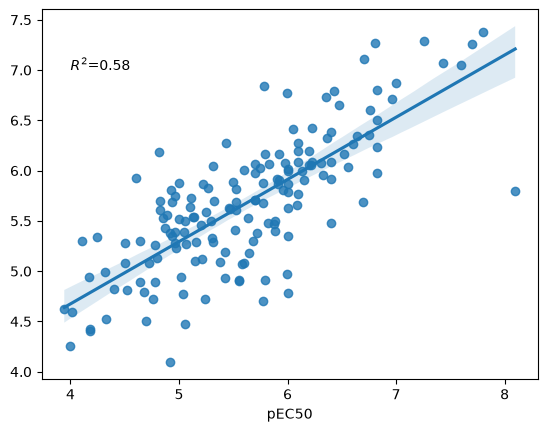

In [35]:
ax = sns.regplot(x=test.pEC50,y=pred)
ax.text(4,7,f"$R^2$={r2:.2f}");

In [36]:
r2_list = []
for i in tqdm(range(0,10)):
    train, test = train_test_split(agg_df)
    lgbm = LGBMRegressor(verbose=-1)
    lgbm.fit(np.stack(train.desc),train.pEC50)
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore",category=UserWarning)
        pred = lgbm.predict(np.stack(test.desc))    
    r2 = r2_score(test.pEC50,pred)
    r2_list.append(r2)

  0%|          | 0/10 [00:00<?, ?it/s]

(0.0, 1.0)

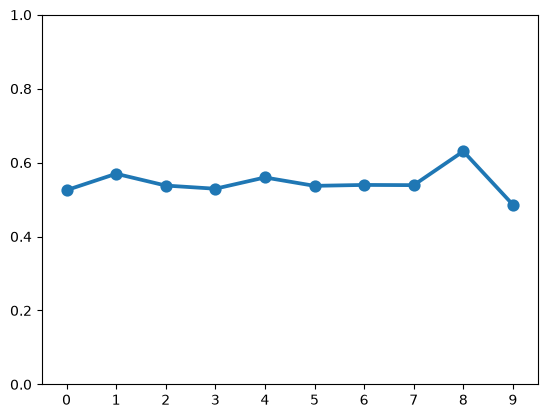

In [37]:
ax = sns.pointplot(r2_list)
ax.set_ylim(0,1)